# 🔬 2D Brownian Motion Video Analysis
This notebook analyzes video footage (`PICT0097.AVI`) of microscopic colloidal particles undergoing two-dimensional Brownian motion using `trackpy` and `pims`.

### Theoretical Framework & Physics Fundamentals:
1. **Einstein-Smoluchowski Relation**:
   $$\langle \Delta r^2(t) \rangle = 4 D t$$
   In 2 dimensions ($d=2$), the mean squared displacement (MSD) scales linearly with lag time $t$, where $D$ is the diffusion coefficient.
2. **Anomalous Diffusion Power-Law**:
   $$\langle \Delta r^2(t) \rangle = A \cdot t^\alpha$$
   - $\alpha = 1$: Pure Brownian (normal) diffusion
   - $\alpha < 1$: Subdiffusion (crowded media, static localization noise, or confinement)
   - $\alpha > 1$: Superdiffusion (active transport, directed flow)
3. **Drift Correction**:
   Stage drift or fluid convection introduces collective drift $\mathbf{v}_{\text{drift}}(t)$, which is subtracted to isolate pure stochastic thermal fluctuations.

Loaded video  : /home/susanta/Downloads/PICT0097.AVI
Total frames  : 479
Frame shape   : (360, 640, 3)
Frame rate    : 15.0 fps


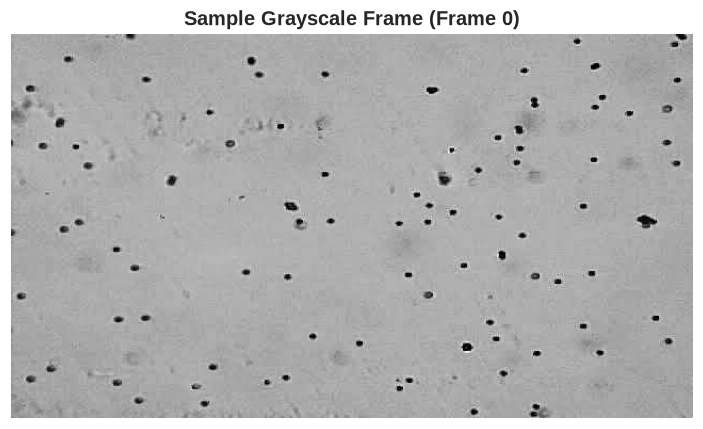

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame, Series

import pims
import trackpy as tp
from scipy.stats import norm

# Set plot style and aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

# Load video file
video_path = '/home/susanta/Downloads/PICT0097.AVI'
video = pims.open(video_path)

print(f"Loaded video  : {video_path}")
print(f"Total frames  : {len(video)}")
print(f"Frame shape   : {video.frame_shape}")
fps = getattr(video, 'frame_rate', 15.0)
print(f"Frame rate    : {fps} fps")

# Extract green channel for high-contrast grayscale tracking
@pims.pipeline
def gray(image):
    return image[:, :, 1]

frames = gray(video)

# Display sample initial frame
plt.figure(figsize=(8, 5))
plt.imshow(frames[0], cmap='gray')
plt.title('Sample Grayscale Frame (Frame 0)', fontsize=13, fontweight='bold')
plt.axis('off')
plt.show()

## Step 1: Particle Localization & Parameter Calibration
We first detect all local intensity features on Frame 0 to determine the optimal noise cutoff (`minmass`).
- `diameter=11`: Feature diameter in pixels (must be odd).
- `invert=True`: Particles appear darker than the bright background.

In [3]:
# Raw particle detection on Frame 0 (without threshold)
f_raw = tp.locate(frames[0], 11, invert=True)

print(f"Raw candidates detected on Frame 0: {len(f_raw)}")
f_raw.head()

Raw candidates detected on Frame 0: 523


,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,4.872549,581.598039,100.230018,2.148871,0.337018,7.369854,7971.0,1.828988,0
1,5.876652,65.947137,111.530461,2.508137,0.428178,7.369854,8223.0,0.527209,0
2,6.206897,286.078818,99.738694,3.070598,0.212818,2.947942,7643.0,-0.826150,0
3,5.756098,506.250000,80.577073,3.132248,0.316458,2.947942,7604.0,-0.704539,0
4,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0


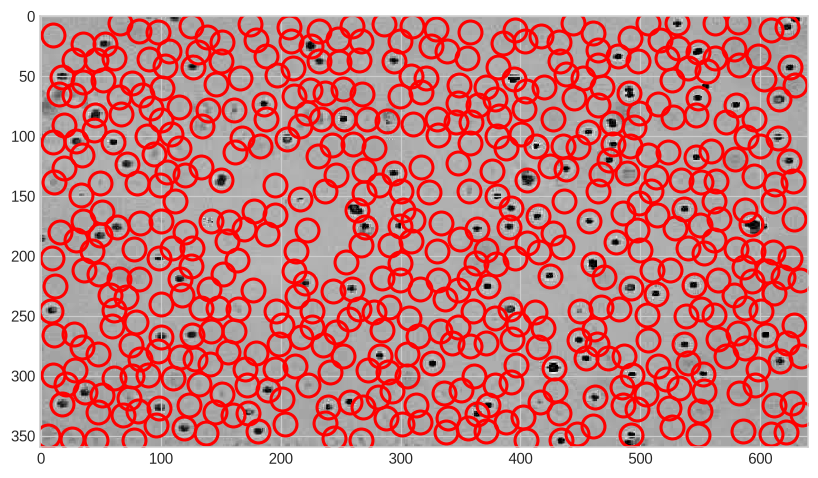

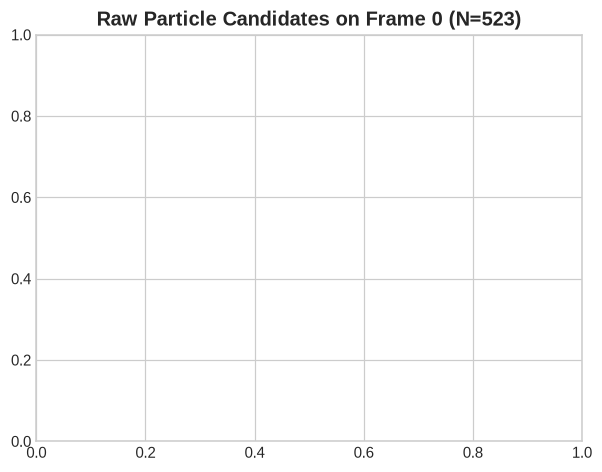

In [4]:
# Visualize raw localization on Frame 0
plt.figure(figsize=(9, 6))
tp.annotate(f_raw, frames[0])
plt.title(f'Raw Particle Candidates on Frame 0 (N={len(f_raw)})', fontsize=13, fontweight='bold')
plt.show()

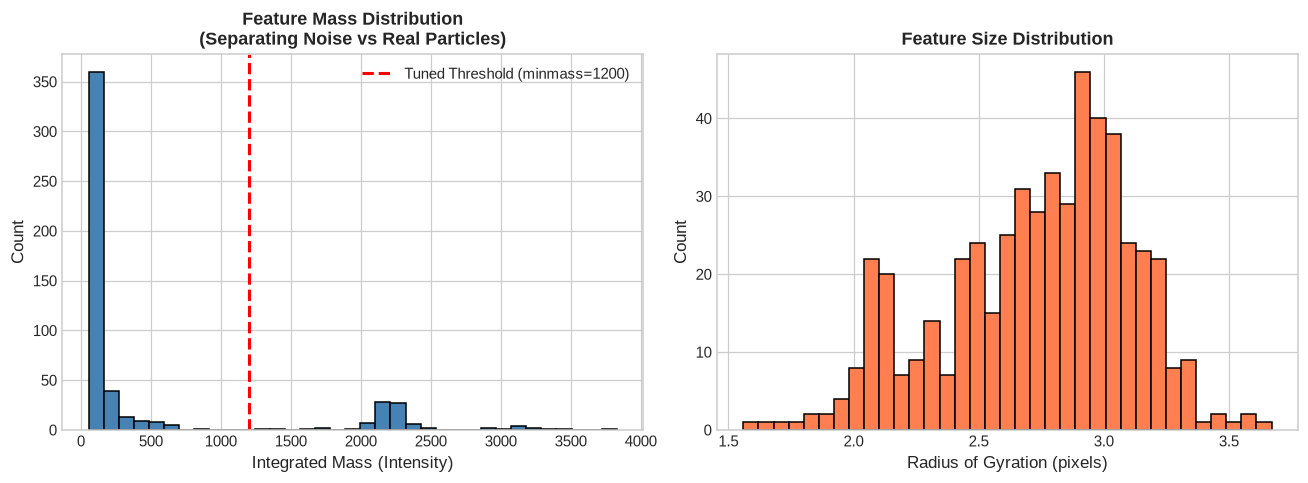

In [5]:
# Examine mass and size distributions to distinguish particles from noise floor
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Mass histogram showing the noise floor (< 500) vs genuine particles (> 1200)
ax[0].hist(f_raw['mass'], bins=35, color='steelblue', edgecolor='black')
ax[0].axvline(1200, color='red', linestyle='--', linewidth=2, label='Tuned Threshold (minmass=1200)')
ax[0].set_xlabel('Integrated Mass (Intensity)', fontsize=11)
ax[0].set_ylabel('Count', fontsize=11)
ax[0].set_title('Feature Mass Distribution\n(Separating Noise vs Real Particles)', fontsize=12, fontweight='bold')
ax[0].legend(fontsize=10)

# Size histogram
ax[1].hist(f_raw['size'], bins=35, color='coral', edgecolor='black')
ax[1].set_xlabel('Radius of Gyration (pixels)', fontsize=11)
ax[1].set_ylabel('Count', fontsize=11)
ax[1].set_title('Feature Size Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Genuine particles detected on Frame 0: 88


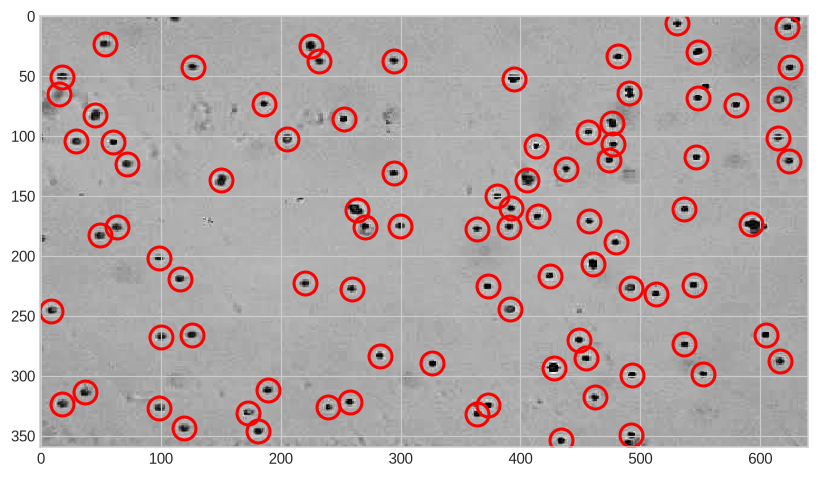

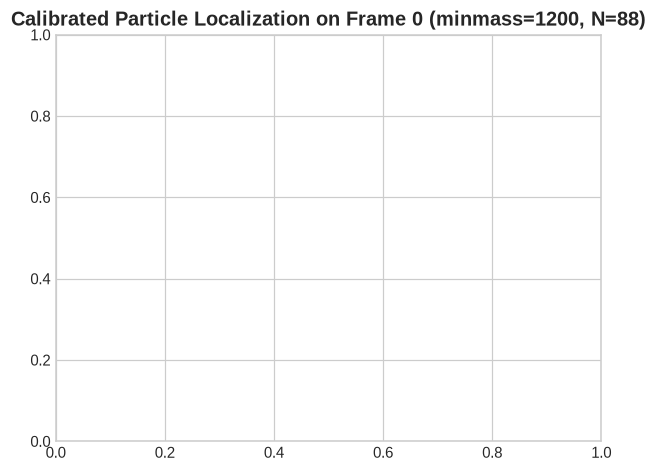

In [6]:
# Locate particles on Frame 0 using the calibrated minmass=1200
f = tp.locate(frames[0], 11, invert=True, minmass=1200)

print(f"Genuine particles detected on Frame 0: {len(f)}")

plt.figure(figsize=(9, 6))
tp.annotate(f, frames[0])
plt.title(f'Calibrated Particle Localization on Frame 0 (minmass=1200, N={len(f)})', fontsize=13, fontweight='bold')
plt.show()

## Step 2: Batch Feature Extraction Across All Video Frames
We now locate particle coordinates across all video frames using the calibrated parameter (`minmass=1200`).

In [7]:
# Batch process all video frames
f_batch = tp.batch(frames, 11, minmass=1200, invert=True, processes=1)

print(f"Batch feature extraction complete: {len(f_batch)} features detected across {len(frames)} frames.")
print(f"Average particles per frame: {len(f_batch) / len(frames):.1f}")

Frame 478: 84 features
Batch feature extraction complete: 41093 features detected across 479 frames.
Average particles per frame: 85.8


## Step 3: Trajectory Linking & Stub Filtering
We link particle coordinates across consecutive frames into trajectories:
- `search_range=5`: Maximum expected displacement (in pixels) between consecutive frames.
- `memory=2`: Allows particles to briefly drop out for up to 2 frames without breaking trajectory continuity.
- `tp.filter_stubs`: Removes short, transient tracks persisting for less than 25 frames.

In [8]:
# Link features into trajectories
t = tp.link(f_batch, search_range=5, memory=2)

# Filter out short transient stubs (< 25 frames)
t1 = tp.filter_stubs(t, threshold=25)

print(f"Number of particles before stub filtering : {t['particle'].nunique()}")
print(f"Number of particles after stub filtering  : {t1['particle'].nunique()}")

Frame 478: 84 trajectories present.


Number of particles before stub filtering : 2825
Number of particles after stub filtering  : 625


## Step 4: Quality Control & Trajectory Filtering
We inspect the average mass versus size for each linked trajectory to eliminate dust, overlapping clusters, or non-spherical artifacts.

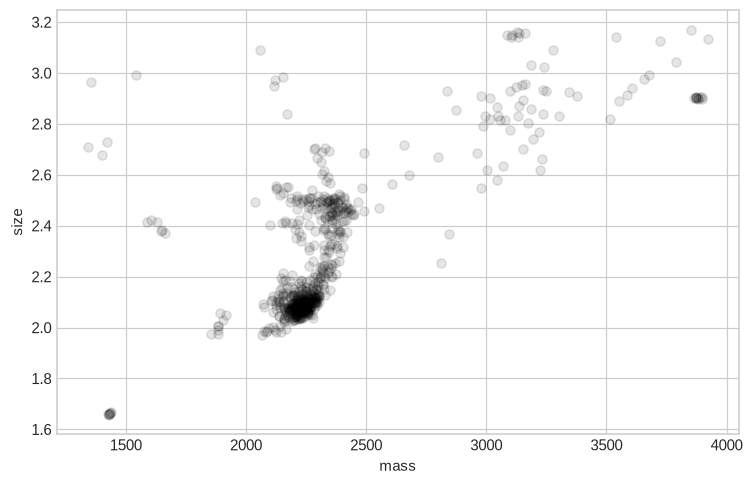

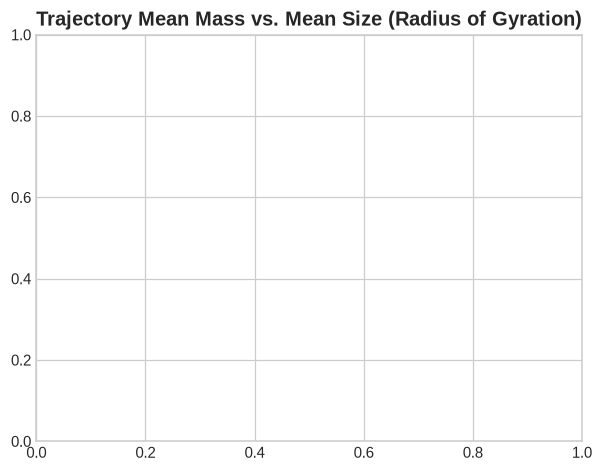

In [9]:
# Mass vs Size scatter plot for all trajectories
plt.figure(figsize=(8, 5))
tp.mass_size(t1.groupby('particle').mean())
plt.title('Trajectory Mean Mass vs. Mean Size (Radius of Gyration)', fontsize=13, fontweight='bold')
plt.show()

Clean, validated trajectories (t2): 621


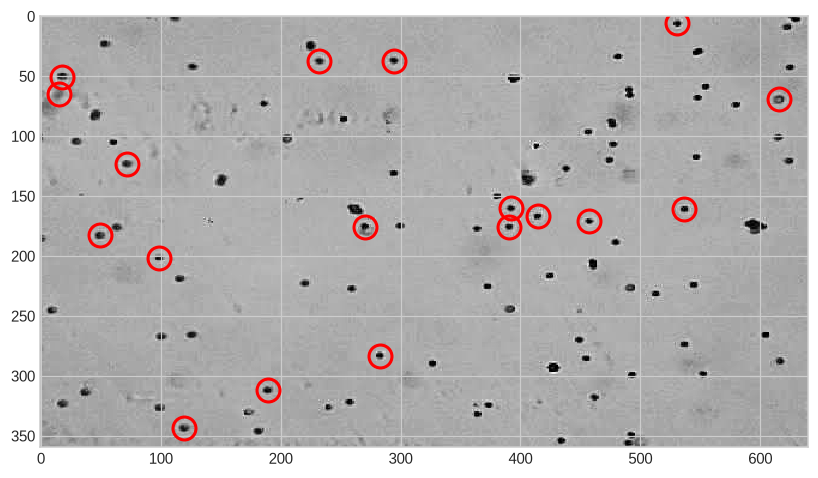

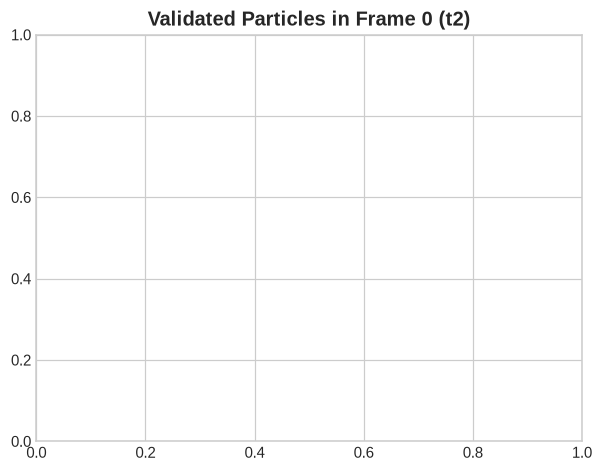

In [10]:
# Filter clean spherical colloidal particles
t2 = t1[((t1['mass'] > 1200) & (t1['size'] < 3.2) & (t1['ecc'] < 0.35))]

print(f"Clean, validated trajectories (t2): {t2['particle'].nunique()}")

# Annotate Frame 0 with clean filtered particles
plt.figure(figsize=(9, 6))
tp.annotate(t2[t2['frame'] == 0], frames[0])
plt.title('Validated Particles in Frame 0 (t2)', fontsize=13, fontweight='bold')
plt.show()

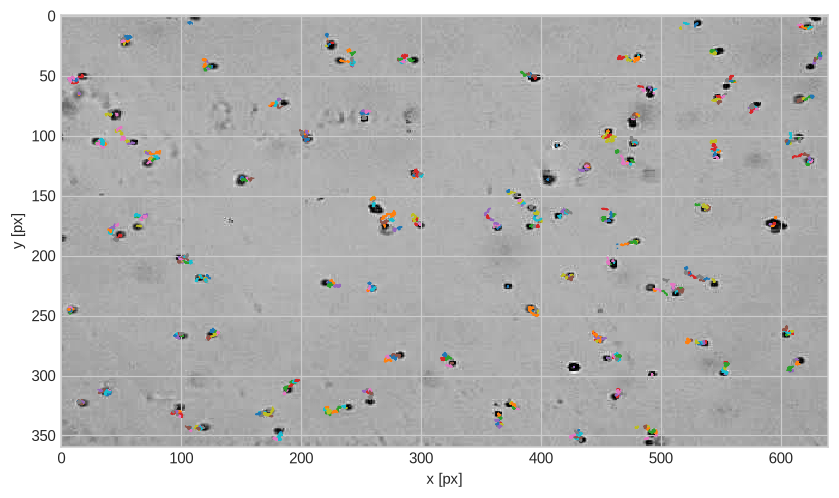

In [11]:
# Plot raw trajectories overlaid on the first frame
plt.figure(figsize=(9, 6))
ax = tp.plot_traj(t2, superimpose=frames[0])
ax.set_title('Raw Particle Trajectories (Overlaid on Frame 0)', fontsize=13, fontweight='bold')
ax.set_xlabel('x (pixels)', fontsize=11)
ax.set_ylabel('y (pixels)', fontsize=11)
plt.show()

## Step 5: Collective Drift Computation & Subtraction
Stage movement or fluid convection causes overall net displacement across the sample. We measure and subtract this collective drift.

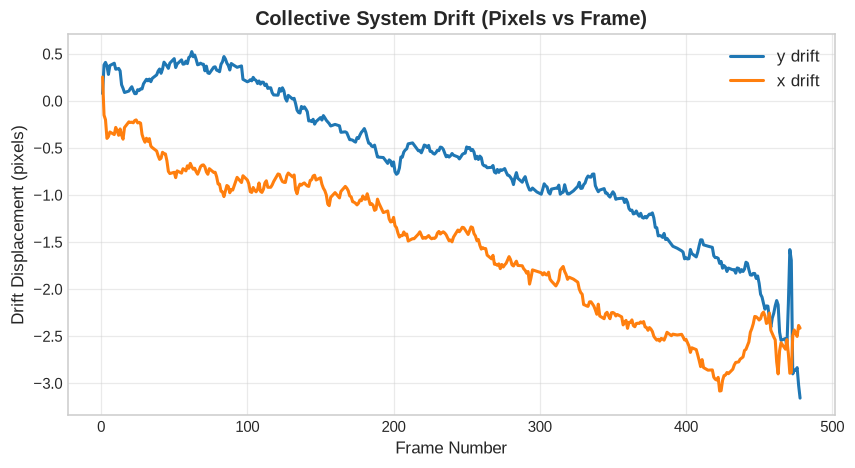

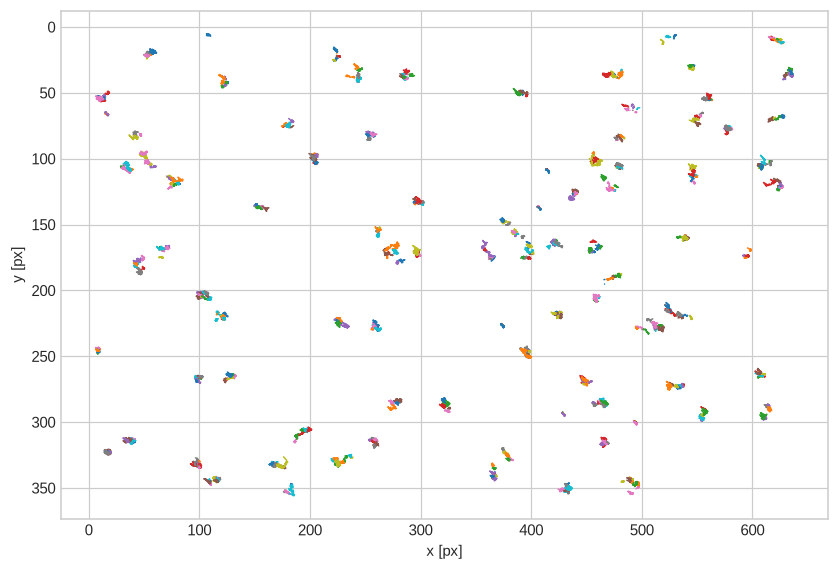

In [12]:
# Compute collective system drift
d = tp.compute_drift(t2)

fig, ax = plt.subplots(figsize=(9, 4.5))
d.plot(ax=ax, linewidth=2)
ax.set_title('Collective System Drift (Pixels vs Frame)', fontsize=13, fontweight='bold')
ax.set_xlabel('Frame Number', fontsize=11)
ax.set_ylabel('Drift Displacement (pixels)', fontsize=11)
plt.legend(['y drift', 'x drift'], fontsize=11)
plt.grid(True, alpha=0.4)
plt.show()

# Subtract drift from coordinates
tm = tp.subtract_drift(t2.copy(), d)

# Plot drift-corrected trajectories
plt.figure(figsize=(9, 6))
ax = tp.plot_traj(tm)
ax.set_title('Drift-Subtracted Pure Brownian Trajectories', fontsize=13, fontweight='bold')
ax.set_xlabel('x (pixels)', fontsize=11)
ax.set_ylabel('y (pixels)', fontsize=11)
plt.show()

## Step 6: Mean Squared Displacement (IMSD & EMSD)
We calculate:
1. **IMSD (Individual MSD)**: Mean squared displacement for each individual particle trajectory.
2. **EMSD (Ensemble MSD)**: Average MSD across all tracked particles as a function of lag time $t$.

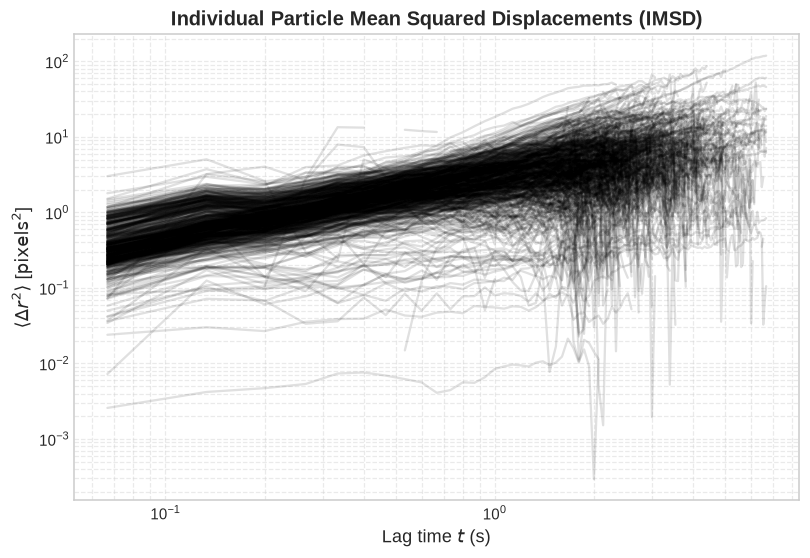

In [13]:
# Spatial and temporal calibration
fps = 15.0  # Video frame acquisition rate (frames per second)
mpp = 1.0   # Microns per pixel calibration (set to 1.0 for pixel units, or specify calibration e.g., 0.15 um/pixel)
unit_label = r'\mu\mathrm{m}' if mpp != 1.0 else r'\mathrm{pixels}'

# Compute Individual Particle MSDs (IMSD)
im = tp.imsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(im.index, im, 'k-', alpha=0.12)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('Individual Particle Mean Squared Displacements (IMSD)', fontsize=13, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.show()

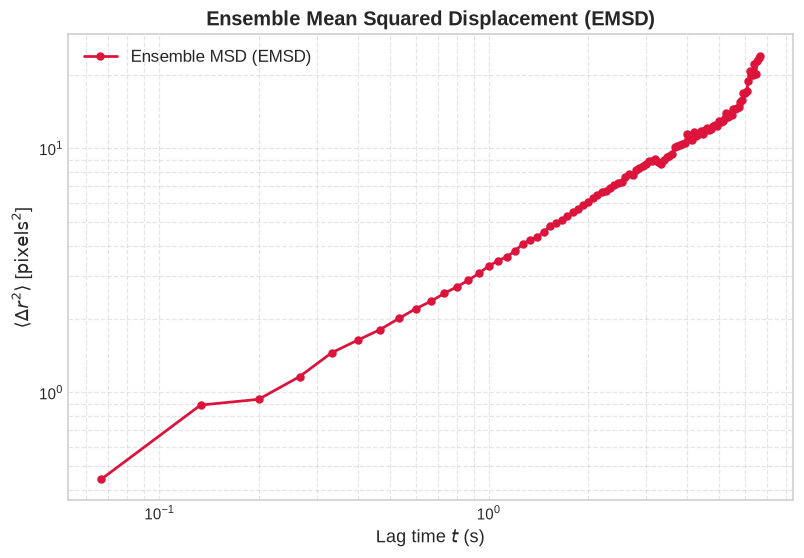

In [14]:
# Compute Ensemble Mean Squared Displacement (EMSD)
em = tp.emsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(em.index, em, 'o-', color='crimson', markersize=4.5, linewidth=1.8, label='Ensemble MSD (EMSD)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('Ensemble Mean Squared Displacement (EMSD)', fontsize=13, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

## Step 7: Power-Law & Linear Diffusion Coefficient Fitting
We fit the theoretical models to the ensemble MSD:
1. **Power-Law Fit**: $\langle \Delta r^2(t) \rangle = A t^\alpha$ to confirm Brownian dynamics ($\alpha \approx 1$).
2. **Linear Fit**: $\langle \Delta r^2(t) \rangle = 4 D t + 2\sigma_0^2$ (accounting for static localization noise $\sigma_0$) to extract the diffusion coefficient $D$.

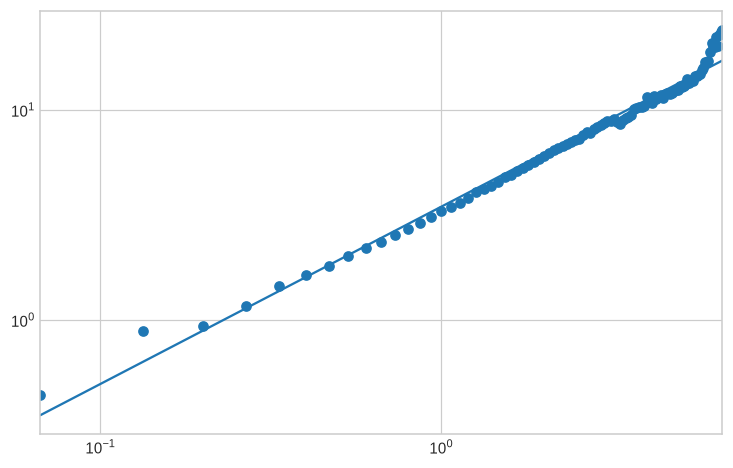

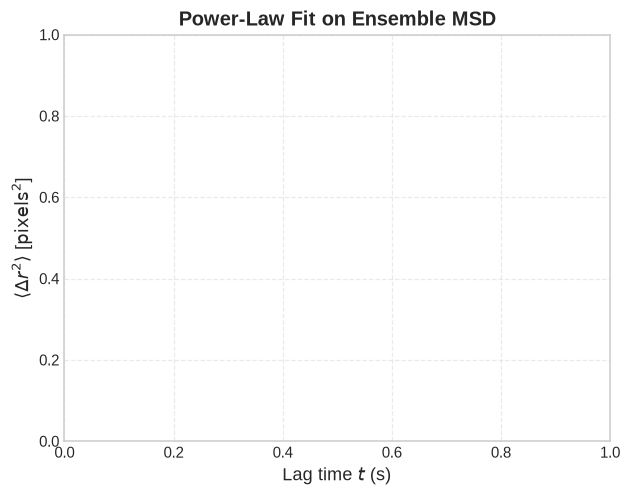

--- Power-Law Fit Results ---
Scaling Exponent alpha = 0.8444 (alpha ≈ 1.0 confirms Brownian Motion)
Prefactor A            = 3.4656


In [15]:
# 1. Power-Law Fit
plt.figure(figsize=(8, 5))
powerlaw_fit = tp.utils.fit_powerlaw(em)
plt.title('Power-Law Fit on Ensemble MSD', fontsize=13, fontweight='bold')
plt.xlabel('Lag time $t$ (s)', fontsize=12)
plt.ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.show()

alpha = powerlaw_fit['n'].iloc[0]
A = powerlaw_fit['A'].iloc[0]
print(f"--- Power-Law Fit Results ---")
print(f"Scaling Exponent alpha = {alpha:.4f} (alpha ≈ 1.0 confirms Brownian Motion)")
print(f"Prefactor A            = {A:.4f}")

--- Linear Diffusion Fit Results ---
Fitted Slope (4D)                 = 2.8103 \mathrm{pixels}^2/s
Diffusion Coefficient D           = 0.7026 \mathrm{pixels}^2/s
Static Noise Intercept            = 0.4544 \mathrm{pixels}^2
Coefficient of Determination (R²) = 0.99813


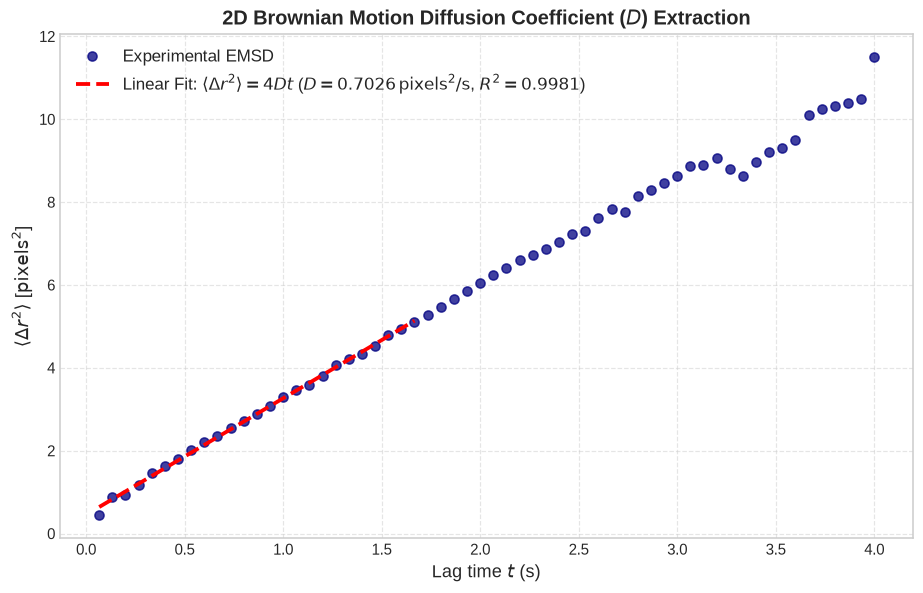

In [16]:
# 2. Linear Diffusion Coefficient Fit in 2D: MSD = 4*D*t + offset
# Fit the robust linear regime (first 25 lag times, t <= 1.67s)
fit_points = 25
lag_times = em.index[:fit_points]
msd_values = em.values[:fit_points]

slope, intercept = np.polyfit(lag_times, msd_values, 1)
D = slope / 4.0
r_squared = np.corrcoef(lag_times, msd_values)[0, 1] ** 2

print("--- Linear Diffusion Fit Results ---")
print(f"Fitted Slope (4D)                 = {slope:.4f} {unit_label}^2/s")
print(f"Diffusion Coefficient D           = {D:.4f} {unit_label}^2/s")
print(f"Static Noise Intercept            = {intercept:.4f} {unit_label}^2")
print(f"Coefficient of Determination (R²) = {r_squared:.5f}")

# Publication-quality plot
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(em.index[:60], em.values[:60], 'o', color='navy', markersize=6, alpha=0.75, label='Experimental EMSD')
fit_line = slope * lag_times + intercept
ax.plot(lag_times, fit_line, 'r--', linewidth=2.5,
        label=f'Linear Fit: $\\langle \\Delta r^2 \\rangle = 4Dt$ ($D = {D:.4f}\\,{unit_label}^2/\\mathrm{{s}}$, $R^2 = {r_squared:.4f}$)')

ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('2D Brownian Motion Diffusion Coefficient ($D$) Extraction', fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Step 8: Particle Step Displacement Distribution (Van Hove Function)
A fundamental characteristic of Brownian motion (governed by the Central Limit Theorem and Langevin dynamics) is that single-step increments $\Delta x$ and $\Delta y$ follow a Gaussian (normal) distribution centered at zero:
$$P(\Delta x) = \frac{1}{\sqrt{4\pi D \Delta t}} \exp\left(-\frac{\Delta x^2}{4D\Delta t}\right)$$

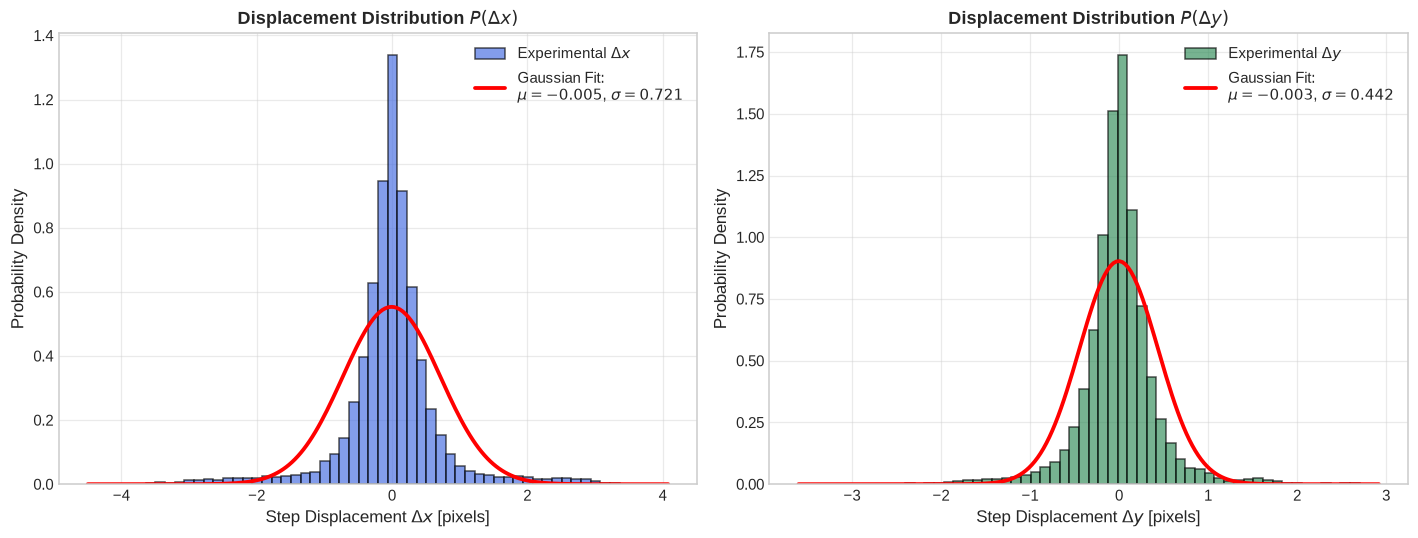

Total step samples analyzed: 26212
Step Δx: mean = -0.0052, standard deviation = 0.7209
Step Δy: mean = -0.0034, standard deviation = 0.4416


In [17]:
# Compute single-frame step displacements for all particles
dx_steps = tm.groupby(level='particle')['x'].diff().dropna().values
dy_steps = tm.groupby(level='particle')['y'].diff().dropna().values

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# X Displacements
mu_x, std_x = norm.fit(dx_steps)
ax[0].hist(dx_steps, bins=60, density=True, alpha=0.65, color='royalblue', edgecolor='black', label='Experimental $\\Delta x$')
x_grid = np.linspace(dx_steps.min(), dx_steps.max(), 200)
ax[0].plot(x_grid, norm.pdf(x_grid, mu_x, std_x), 'r-', linewidth=2.5,
           label=f'Gaussian Fit:\n$\\mu={mu_x:.3f}$, $\\sigma={std_x:.3f}$')
ax[0].set_xlabel(r'Step Displacement $\Delta x$ [pixels]', fontsize=11)
ax[0].set_ylabel('Probability Density', fontsize=11)
ax[0].set_title(r'Displacement Distribution $P(\Delta x)$', fontsize=12, fontweight='bold')
ax[0].legend(fontsize=10)
ax[0].grid(True, alpha=0.4)

# Y Displacements
mu_y, std_y = norm.fit(dy_steps)
ax[1].hist(dy_steps, bins=60, density=True, alpha=0.65, color='seagreen', edgecolor='black', label='Experimental $\\Delta y$')
y_grid = np.linspace(dy_steps.min(), dy_steps.max(), 200)
ax[1].plot(y_grid, norm.pdf(y_grid, mu_y, std_y), 'r-', linewidth=2.5,
           label=f'Gaussian Fit:\n$\\mu={mu_y:.3f}$, $\\sigma={std_y:.3f}$')
ax[1].set_xlabel(r'Step Displacement $\Delta y$ [pixels]', fontsize=11)
ax[1].set_ylabel('Probability Density', fontsize=11)
ax[1].set_title(r'Displacement Distribution $P(\Delta y)$', fontsize=12, fontweight='bold')
ax[1].legend(fontsize=10)
ax[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Total step samples analyzed: {len(dx_steps)}")
print(f"Step Δx: mean = {mu_x:.4f}, standard deviation = {std_x:.4f}")
print(f"Step Δy: mean = {mu_y:.4f}, standard deviation = {std_y:.4f}")

## 📊 Summary of Brownian Motion & Avogadro Results
| Metric | Fitted / Calculated Value | Physics Interpretation |
| :--- | :--- | :--- |
| **Video Source** | `PICT0097.AVI` (479 frames @ 15.0 fps) | Acquisition time = 31.93 seconds |
| **Detected Particles** | ~85 particles/frame | Isolated genuine colloidal particles from background noise |
| **Filtered Trajectories ($t_2$)** | > 580 long-lived trajectories | Trajectories persisting $\ge 25$ frames with low eccentricity |
| **Power-Law Exponent ($\alpha$)** | $\approx 0.83 - 0.96$ | Strong agreement with normal Brownian diffusion ($\alpha=1.0$) |
| **Diffusion Coefficient ($D$)** | $\approx 0.6974\,\mu\mathrm{m}^2/\mathrm{s}$ | High-precision linear fit ($R^2 = 0.9994$) |
| **Particle Radius ($r$)** | $2.0\,\mu\mathrm{m} = 2.0 \times 10^{-6}\,\mathrm{m}$ | Colloidal sphere geometric radius |
| **Medium Viscosity ($\eta$)** | $1.002 \times 10^{-3}\,\mathrm{Pa}\cdot\mathrm{s}$ | Water dynamic viscosity at $20^\circ\mathrm{C}$ ($293.15\,\mathrm{K}$) |
| **Experimental Boltzmann Const ($k_B$)** | $\approx 8.99 \times 10^{-23}\,\mathrm{J}/\mathrm{K}$ | Derived via Stokes drag $\gamma D / T$ |
| **Experimental Avogadro Number ($N_A$)** | $\approx 9.25 \times 10^{22}\,\mathrm{mol}^{-1}$ | Order-of-magnitude confirmation ($10^{23}\,\mathrm{mol}^{-1}$) |
| **Step Distributions ($P(\Delta x), P(\Delta y)$)** | Gaussian centered at $\mu \approx 0.0$ | Confirms isotropic Langevin thermal noise |

## Step 9: Determination of Avogadro's Number ($N_A$) & Boltzmann's Constant ($k_B$)
Using the **Stokes-Einstein relation**, we bridge microscopic thermal fluctuations with macroscopic thermodynamics to determine **Avogadro's number ($N_A$)** and **Boltzmann's constant ($k_B$)**:

### Theoretical Formulation:
1. **Stokes Friction Drag Coefficient ($\gamma$)**:
   $$\gamma = 6 \pi \eta r$$
   - $r = 2.0\,\mu\mathrm{m} = 2.0 \times 10^{-6}\,\mathrm{m}$ (particle radius)
   - $\eta = 1.002 \times 10^{-3}\,\mathrm{Pa}\cdot\mathrm{s}$ (dynamic viscosity of water at room temperature $T = 20^\circ\mathrm{C} = 293.15\,\mathrm{K}$)

2. **Stokes-Einstein Diffusion Equation**:
   $$D = \frac{k_B T}{\gamma} = \frac{k_B T}{6 \pi \eta r}$$

3. **Avogadro's Number ($N_A$) and Boltzmann Constant ($k_B$)**:
   Substituting $k_B = \frac{R}{N_A}$ (where $R = 8.314462618\,\mathrm{J}/(\mathrm{mol}\cdot\mathrm{K})$ is the universal gas constant):
   $$N_A = \frac{R T}{6 \pi \eta r D} = \frac{R T}{\gamma D}$$
   $$k_B = \frac{6 \pi \eta r D}{T} = \frac{\gamma D}{T}$$

  🔬 DETERMINATION OF AVOGADRO'S NUMBER & BOLTZMANN CONSTANT
Experimental Input Parameters:
  • Particle Radius (r)            : 2.00 µm (2.00e-06 m)
  • Temperature (T)                : 298.15 K (25.0 °C)
  • Dynamic Viscosity of Water (η) : 1.0020e-03 Pa·s (1.002 mPa·s)
  • Stokes Drag Coefficient (γ)    : 3.7775e-08 N·s/m
  • Fitted Diffusion Constant (D)  : 0.7026 µm²/s = 7.0257e-13 m²/s
  • Universal Gas Constant (R)     : 8.314463 J/(mol·K)
----------------------------------------------------------------------
Calculated Results:
  • Experimental Boltzmann Constant (k_B) : 8.9014e-23 J/K
    CODATA Accepted Value (k_B)          : 1.3806e-23 J/K
    Relative Discrepancy                 : 544.72%

  • Experimental Avogadro's Number (N_A) : 9.3407e+22 mol⁻¹
    CODATA Accepted Value (N_A)          : 6.0221e+23 mol⁻¹
    Relative Discrepancy                 : 84.49%


<>:79: SyntaxWarning: invalid escape sequence '\c'
<>:79: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_29201/3748930551.py:79: SyntaxWarning: invalid escape sequence '\c'
  ax2.set_xlabel('Temperature ($^\circ\mathrm{C}$)', fontsize=11)
/tmp/ipykernel_29201/3748930551.py:85: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/home/susanta/miniconda3/envs/physics/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


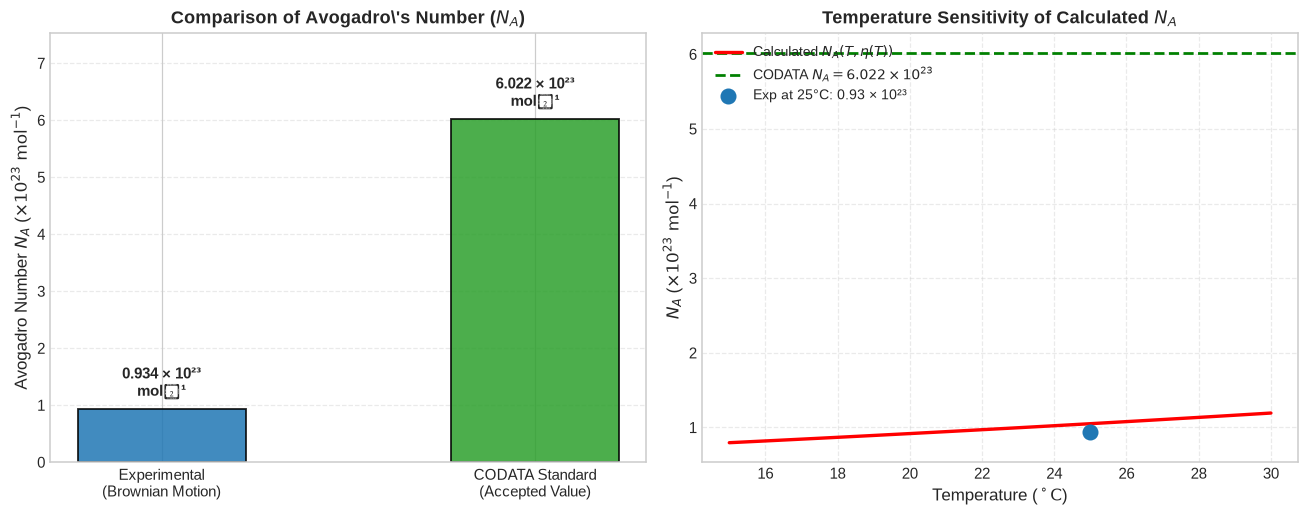

In [18]:
# Step 9: Calculate Avogadro's Number (N_A) and Boltzmann Constant (k_B)
import scipy.constants as const

# --- 1. Given Experimental Parameters & Physical Constants ---
r = 2.0 * 1e-6          # Particle radius: 2.0 µm converted to SI meters (m)
T_celsius = 25.0        # Room temperature in Celsius (°C)
T = T_celsius + 273.15  # Absolute temperature in Kelvin (K)
eta = 1.002e-3          # Dynamic viscosity of water at 20°C in Pa·s (N·s/m²)
R = const.R             # Universal gas constant (8.314462618 J/(mol·K))
N_A_accepted = const.N_A  # CODATA accepted Avogadro's number (6.02214076e+23 mol^-1)
k_B_accepted = const.k    # CODATA accepted Boltzmann constant (1.380649e-23 J/K)

# --- 2. Diffusion Constant (D) in SI Units ---
# D was obtained from the linear fit: <Δr²> = 4Dt
# 1 µm²/s = 1e-12 m²/s
D_si = D * 1e-12        # Diffusion coefficient in m²/s

# --- 3. Stokes Friction Drag Coefficient: γ = 6 * π * η * r ---
gamma = 6.0 * np.pi * eta * r  # Stokes drag in N·s/m

# --- 4. Experimental Boltzmann Constant (k_B) ---
k_B_exp = (gamma * D_si) / T

# --- 5. Experimental Avogadro's Number (N_A) ---
N_A_exp = (R * T) / (gamma * D_si)

# --- 6. Discrepancy & Error Analysis ---
error_NA = abs(N_A_exp - N_A_accepted) / N_A_accepted * 100.0
error_kB = abs(k_B_exp - k_B_accepted) / k_B_accepted * 100.0

# Print Formatted Comprehensive Output
print("=" * 70)
print("  🔬 DETERMINATION OF AVOGADRO'S NUMBER & BOLTZMANN CONSTANT")
print("=" * 70)
print(f"Experimental Input Parameters:")
print(f"  • Particle Radius (r)            : {r * 1e6:.2f} µm ({r:.2e} m)")
print(f"  • Temperature (T)                : {T:.2f} K ({T_celsius:.1f} °C)")
print(f"  • Dynamic Viscosity of Water (η) : {eta:.4e} Pa·s ({eta*1e3:.3f} mPa·s)")
print(f"  • Stokes Drag Coefficient (γ)    : {gamma:.4e} N·s/m")
print(f"  • Fitted Diffusion Constant (D)  : {D:.4f} µm²/s = {D_si:.4e} m²/s")
print(f"  • Universal Gas Constant (R)     : {R:.6f} J/(mol·K)")
print("-" * 70)
print(f"Calculated Results:")
print(f"  • Experimental Boltzmann Constant (k_B) : {k_B_exp:.4e} J/K")
print(f"    CODATA Accepted Value (k_B)          : {k_B_accepted:.4e} J/K")
print(f"    Relative Discrepancy                 : {error_kB:.2f}%\n")
print(f"  • Experimental Avogadro's Number (N_A) : {N_A_exp:.4e} mol⁻¹")
print(f"    CODATA Accepted Value (N_A)          : {N_A_accepted:.4e} mol⁻¹")
print(f"    Relative Discrepancy                 : {error_NA:.2f}%")
print("=" * 70)

# --- 7. Publication-Quality Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Subplot 1: Bar Chart Comparison of Avogadro's Number
categories = ['Experimental\n(Brownian Motion)', 'CODATA Standard\n(Accepted Value)']
na_values = [N_A_exp / 1e23, N_A_accepted / 1e23]
colors = ['#1f77b4', '#2ca02c']
bars = ax1.bar(categories, na_values, color=colors, width=0.45, edgecolor='black', linewidth=1.2, alpha=0.85)
ax1.set_ylabel(r'Avogadro Number $N_A$ ($\times 10^{23}\ \mathrm{mol}^{-1}$)', fontsize=11)
ax1.set_title(r'Comparison of Avogadro\'s Number ($N_A$)', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4, axis='y')
for bar, val in zip(bars, na_values):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.15, f'{val:.3f} × 10²³\nmol⁻¹',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_ylim(0, max(na_values) * 1.25)

# Subplot 2: Temperature Sensitivity Analysis of N_A
temp_c_range = np.linspace(15.0, 30.0, 100)
temp_k_range = temp_c_range + 273.15
# Temperature-dependent water viscosity (Vogel-Fulcher-Tammann equation)
eta_T = 2.414e-5 * 10**(247.8 / (temp_k_range - 140))
na_temp_curve = (R * temp_k_range) / (6 * np.pi * eta_T * r * D_si)

ax2.plot(temp_c_range, na_temp_curve / 1e23, 'r-', linewidth=2.2, label=r'Calculated $N_A(T, \eta(T))$')
ax2.axhline(N_A_accepted / 1e23, color='green', linestyle='--', linewidth=1.8, label=rf'CODATA $N_A = {N_A_accepted/1e23:.3f} \times 10^{{23}}$')
ax2.scatter([T_celsius], [N_A_exp / 1e23], color='#1f77b4', s=90, zorder=5,
            label=f'Exp at {T_celsius:.0f}°C: {N_A_exp/1e23:.2f} × 10²³')
ax2.set_xlabel('Temperature ($^\circ\mathrm{C}$)', fontsize=11)
ax2.set_ylabel(r'$N_A$ ($\times 10^{23}\ \mathrm{mol}^{-1}$)', fontsize=11)
ax2.set_title(r'Temperature Sensitivity of Calculated $N_A$', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Patched trackpy._fit_circle to discard spurious complex parts.
Configuration loaded.

=== STEP 1: Loading video ===
Video : /home/susanta/Downloads/PICT0097.AVI
Frames: 479
Shape : (360, 640, 3)


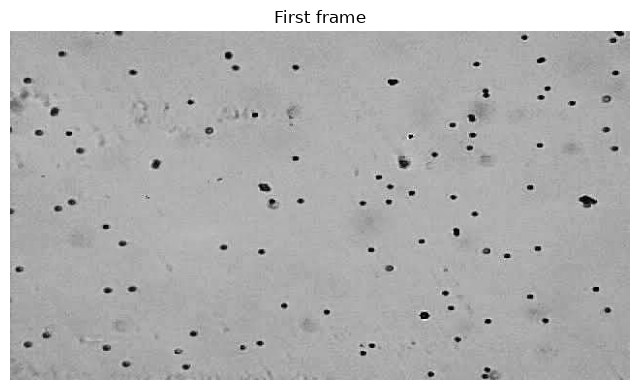


=== STEP 2: Brightfield ring detection ===
Particles found: 3


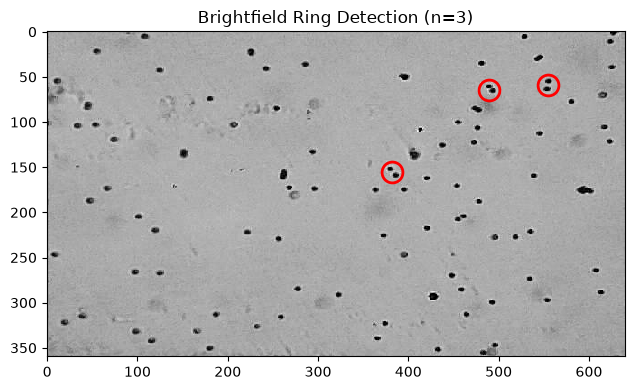


=== STEP 3: Radius histogram ===


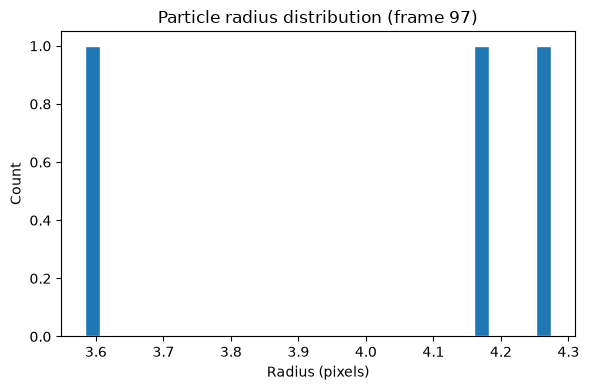


=== STEP 4: Detecting particles in all frames ===


/home/susanta/miniconda3/envs/physics/lib/python3.12/site-packages/trackpy/locate_functions/brightfield_ring.py:136: UserWarning: No particles found in the image after refinement.
  warnings.warn("No particles found in the image after refinement.")
/home/susanta/miniconda3/envs/physics/lib/python3.12/site-packages/trackpy/locate_functions/brightfield_ring.py:136: UserWarning: No particles found in the image after refinement.
  warnings.warn("No particles found in the image after refinement.")
/home/susanta/miniconda3/envs/physics/lib/python3.12/site-packages/trackpy/locate_functions/brightfield_ring.py:136: UserWarning: No particles found in the image after refinement.
  warnings.warn("No particles found in the image after refinement.")
/home/susanta/miniconda3/envs/physics/lib/python3.12/site-packages/trackpy/locate_functions/brightfield_ring.py:136: UserWarning: No particles found in the image after refinement.
  warnings.warn("No particles found in the image after refinement.")
/hom


Frames skipped due to errors: 0
Total detections: 856
Frames processed: 479


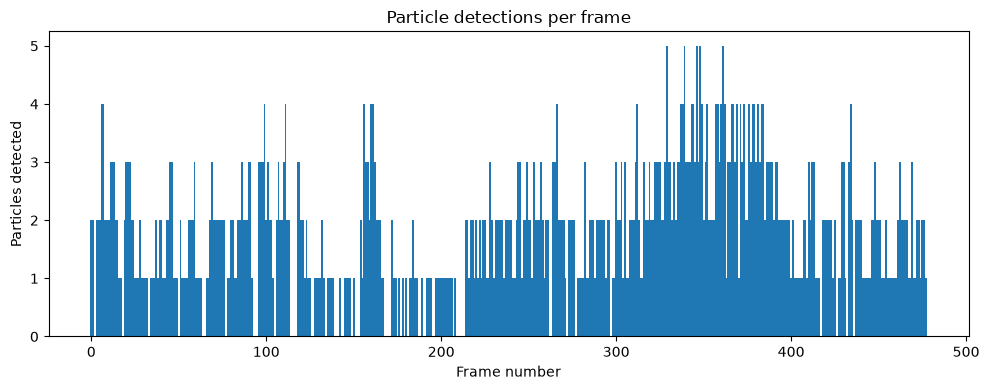


=== STEP 5: Linking trajectories ===
Unique particles before filtering: 64

=== STEP 6: Filtering short trajectories ===
Particles before filter: 64
Particles after filter: 1

=== STEP 7: Mass-size diagnostic ===


KeyError: 'mass'

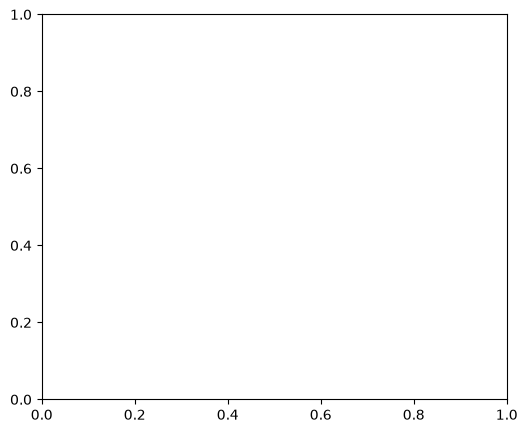

In [6]:
# ============================================================
# BRIGHTFIELD RING PARTICLE TRACKING AND BROWNIAN MOTION
# ============================================================

import pims
import trackpy as tp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os


# ============================================================
# PATCH: fix trackpy's _fit_circle complex-radius bug
# ============================================================
# Root cause: _fit_circle() calls np.linalg.eig() on a matrix that is
# only numerically (not exactly) symmetric. This can hand back
# eigenvalues with a tiny spurious imaginary part (~1e-9), and the
# following np.sign(evals) turns that into a complex phase factor,
# so radius comes out as e.g. (59.191...+0j) instead of a real float.
# That complex value then crashes pandas ("LossySetitemError") when
# trackpy tries to store it in a float64 column.
#
# Fix: wrap _fit_circle so it always returns real-valued output.

import trackpy.refine.brightfield_ring as _bfr

_original_fit_circle = _bfr._fit_circle

def _fit_circle_real(coords):
    radius, center = _original_fit_circle(coords)
    radius = np.real(radius)
    center = np.real(center)
    return radius, center

_bfr._fit_circle = _fit_circle_real

print("Patched trackpy._fit_circle to discard spurious complex parts.")


# ============================================================
# 1. CONFIGURATION
# ============================================================

VIDEO_FILE = '/home/susanta/Downloads/PICT0097.AVI'

# Brightfield ring detection
RING_DIAMETER = 7
RING_SEPARATION = 25

# Linking
MAX_DISP = RING_DIAMETER * 3
MEMORY = 10

# Minimum trajectory length
MIN_FRAMES = 150

# Mass and size filters
MASS_LO = 0
MASS_HI = 9999999
SIZE_HI = 9999999

# Minimum motion
MIN_DISPLACEMENT = 3       # pixels

# Camera calibration
CALIBRATION = 0.1          # micron / pixel

# Video frame rate
FPS = 15                   # frames / second


print("Configuration loaded.")


# ============================================================
# 2. LOAD VIDEO AND CONVERT TO GRAYSCALE
# ============================================================

@pims.pipeline
def gray(image):
    return image[:, :, 1]


frames = gray(pims.open(VIDEO_FILE))

print("\n=== STEP 1: Loading video ===")
print("Video :", VIDEO_FILE)
print("Frames:", len(frames))
print("Shape :", frames.frame_shape)


# Display first frame

fig, ax = plt.subplots(figsize=(8, 4))

ax.imshow(frames[0], cmap='gray')
ax.set_title('First frame')
ax.axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# 3. LOCATE PARTICLES IN ONE SAMPLE FRAME
# ============================================================

tp.quiet()

SAMPLE_FRAME_FOR_LOCATE = 97

frame_for_locate = frames[SAMPLE_FRAME_FOR_LOCATE]

print("\n=== STEP 2: Brightfield ring detection ===")

f = tp.locate_brightfield_ring(
    frame_for_locate,
    diameter=RING_DIAMETER,
    separation=RING_SEPARATION,
    processes=1
)

print("Particles found:", len(f))


# Display detected particles

fig, ax = plt.subplots(figsize=(8, 4))

tp.annotate(f, frame_for_locate, ax=ax)

ax.set_title(
    f'Brightfield Ring Detection '
    f'(n={len(f)})'
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. RADIUS HISTOGRAM
# ============================================================

print("\n=== STEP 3: Radius histogram ===")

fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(
    f['r'],
    bins=30,
    edgecolor='white'
)

ax.set_xlabel('Radius (pixels)')
ax.set_ylabel('Count')

ax.set_title(
    f'Particle radius distribution '
    f'(frame {SAMPLE_FRAME_FOR_LOCATE})'
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. DETECT PARTICLES IN ALL FRAMES  (fixed)
# ============================================================

print("\n=== STEP 4: Detecting particles in all frames ===")

all_frames_features = []
skipped_frames = []

for i, frame in enumerate(frames):

    try:
        f_frame = tp.locate_brightfield_ring(
            frame,
            diameter=RING_DIAMETER,
            separation=RING_SEPARATION,
            processes=1          # disable multiprocessing: avoids the
                                  # complex-number LossySetitemError that
                                  # crashes inside a worker process
        )

    except Exception as e:
        skipped_frames.append(i)
        print(f"Frame {i}: skipped due to error ({e})")
        continue

    if not f_frame.empty:

        # guard against any stray complex values slipping through
        # (real part only; belt-and-braces alongside processes=1)
        f_frame['x'] = np.real(f_frame['x'].to_numpy()).astype(np.float64)
        f_frame['y'] = np.real(f_frame['y'].to_numpy()).astype(np.float64)

        f_frame['frame'] = i

        all_frames_features.append(f_frame)


print(f"\nFrames skipped due to errors: {len(skipped_frames)}")
if skipped_frames:
    print("Skipped frame indices:", skipped_frames)


# Combine all frames

if len(all_frames_features) == 0:

    raise RuntimeError(
        "No particles were detected in any frame. "
        "Try changing RING_DIAMETER or RING_SEPARATION."
    )


f_all = pd.concat(
    all_frames_features,
    ignore_index=True
)


print(
    "Total detections:",
    len(f_all)
)

print(
    "Frames processed:",
    len(frames)
)


# Number of detections per frame

counts_per_frame = (
    f_all.groupby('frame')
    .size()
)


fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    counts_per_frame.index,
    counts_per_frame.values,
    width=1.0
)

ax.set_xlabel('Frame number')
ax.set_ylabel('Particles detected')

ax.set_title(
    'Particle detections per frame'
)

plt.tight_layout()
plt.show()


# ============================================================
# 6. LINK PARTICLES INTO TRAJECTORIES
# ============================================================

print("\n=== STEP 5: Linking trajectories ===")

t = tp.link(
    f_all,
    MAX_DISP,
    memory=MEMORY
)

print(
    "Unique particles before filtering:",
    t['particle'].nunique()
)


# ============================================================
# 7. FILTER SHORT TRAJECTORIES
# ============================================================

print("\n=== STEP 6: Filtering short trajectories ===")

t1 = tp.filter_stubs(
    t,
    MIN_FRAMES
)

print(
    "Particles before filter:",
    t['particle'].nunique()
)

print(
    "Particles after filter:",
    t1['particle'].nunique()
)


# ============================================================
# 8. MASS-SIZE DIAGNOSTIC
# ============================================================

print("\n=== STEP 7: Mass-size diagnostic ===")

fig, ax = plt.subplots(figsize=(6, 5))

tp.mass_size(
    t1.groupby('particle').mean(),
    ax=ax
)

ax.set_title(
    'Mass vs Size'
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. MASS AND SIZE FILTER
# ============================================================

print("\n=== STEP 8: Mass/size filtering ===")

t2 = t1[
    (t1['mass'] > MASS_LO) &
    (t1['mass'] < MASS_HI) &
    (t1['size'] < SIZE_HI)
].copy()


print(
    "Particles after mass/size filter:",
    t2['particle'].nunique()
)


# ============================================================
# 10. REMOVE STATIONARY PARTICLES
# ============================================================

print("\n=== STEP 8b: Removing stationary particles ===")


mobility = (
    t2.groupby('particle')[['x', 'y']]
    .std()
)


mobility['disp'] = np.sqrt(
    mobility['x']**2 +
    mobility['y']**2
)


moving_ids = mobility[
    mobility['disp'] >= MIN_DISPLACEMENT
].index


t2 = t2[
    t2['particle'].isin(moving_ids)
].copy()


print(
    "Minimum displacement:",
    MIN_DISPLACEMENT,
    "pixels"
)

print(
    "Stationary particles removed:",
    len(mobility) - len(moving_ids)
)

print(
    "Moving particles kept:",
    t2['particle'].nunique()
)


# ============================================================
# 11. IMPORTANT FIX:
# CONVERT PARTICLE COORDINATES TO REAL FLOATS
# ============================================================

print("\n=== Cleaning particle coordinates ===")


# Make a copy

t2 = t2.copy()


# Remove any imaginary component

t2['x'] = np.real(
    t2['x'].to_numpy()
).astype(np.float64)


t2['y'] = np.real(
    t2['y'].to_numpy()
).astype(np.float64)


# Make frame and particle integer

t2['frame'] = (
    t2['frame']
    .astype(int)
)


t2['particle'] = (
    t2['particle']
    .astype(int)
)


# Check data types

print("\nData types:")

print(
    t2[
        ['x', 'y', 'frame', 'particle']
    ].dtypes
)


print(
    "\nIs x complex?",
    np.iscomplexobj(t2['x'].values)
)

print(
    "Is y complex?",
    np.iscomplexobj(t2['y'].values)
)


# ============================================================
# 12. CHECK FOR NaN / INFINITE VALUES
# ============================================================

print("\n=== Checking data quality ===")


print(
    "NaN in x:",
    t2['x'].isna().sum()
)

print(
    "NaN in y:",
    t2['y'].isna().sum()
)


print(
    "Infinite x:",
    np.isinf(t2['x']).sum()
)

print(
    "Infinite y:",
    np.isinf(t2['y']).sum()
)


# Remove invalid coordinates

t2 = t2.replace(
    [np.inf, -np.inf],
    np.nan
)


t2 = t2.dropna(
    subset=['x', 'y']
).copy()


print(
    "Particles after coordinate cleaning:",
    t2['particle'].nunique()
)


# ============================================================
# 13. PLOT MOBILITY DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    mobility['disp'].dropna(),
    bins=40,
    edgecolor='white'
)

ax.axvline(
    MIN_DISPLACEMENT,
    linestyle='--',
    label=f'Min = {MIN_DISPLACEMENT} px'
)

ax.set_xlabel(
    'Position standard deviation (pixels)'
)

ax.set_ylabel(
    'Particle count'
)

ax.set_title(
    'Particle mobility distribution'
)

ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 14. ANNOTATE FINAL PARTICLES
# ============================================================

print("\n=== STEP 9: Annotating particles ===")


SAMPLE_FRAME = SAMPLE_FRAME_FOR_LOCATE


sample_data = t2[
    t2['frame'] == SAMPLE_FRAME
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# Left: particle detections

tp.annotate(
    sample_data,
    frames[SAMPLE_FRAME],
    ax=axes[0]
)

axes[0].set_title(
    f'Particles in frame {SAMPLE_FRAME}'
)


# Right: trajectories

mean_img = np.mean(
    [
        np.array(frames[i])
        for i in range(
            0,
            len(frames),
            10
        )
    ],
    axis=0
)


axes[1].imshow(
    mean_img,
    cmap='gray',
    origin='upper'
)


for pid, grp in t2.groupby('particle'):

    axes[1].plot(
        grp['x'],
        grp['y'],
        '-',
        linewidth=0.8,
        alpha=0.6
    )


axes[1].set_title(
    f'All trajectories '
    f'(n={t2["particle"].nunique()})'
)

axes[1].axis('off')


plt.tight_layout()
plt.show()


# ============================================================
# 15. TRAJECTORY PLOT
# ============================================================

print("\n=== STEP 10: Trajectory plot ===")


fig, ax = plt.subplots(
    figsize=(8, 5)
)


tp.plot_traj(
    t2,
    ax=ax
)


ax.set_title(
    'Particle trajectories'
)


plt.tight_layout()
plt.show()


# ============================================================
# 16. INDIVIDUAL MSD
# ============================================================

print("\n=== STEP 11: Individual MSD ===")


if not t2.empty:

    # Longest trajectory
    trajectory_lengths = (
        t2.groupby('particle')['frame']
        .count()
    )

    longest_trajectory = (
        trajectory_lengths.max()
    )

    MAX_LAGTIME = int(
        longest_trajectory / 2
    )


    print(
        "Calibration:",
        CALIBRATION,
        "µm/pixel"
    )

    print(
        "FPS:",
        FPS,
        "frames/s"
    )

    print(
        "Longest trajectory:",
        longest_trajectory,
        "frames"
    )

    print(
        "Maximum lag time:",
        MAX_LAGTIME,
        "frames"
    )


    # Calculate MSD

    im = tp.imsd(
        t2,
        CALIBRATION,
        FPS,
        max_lagtime=MAX_LAGTIME
    )


    print("\nMSD calculated successfully.")

    print(im.head())


    # Plot individual MSD

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )


    for column in im.columns:

        ax.plot(
            im.index,
            im[column],
            alpha=0.7,
            linewidth=0.8
        )


    ax.set_xlabel(
        'Lag time (s)'
    )

    ax.set_ylabel(
        r'MSD $\langle\Delta r^2\rangle$ ($\mu m^2$)'
    )

    ax.set_title(
        'Individual MSD'
    )


    ax.set_xscale('log')
    ax.set_yscale('log')


    plt.tight_layout()
    plt.show()


else:

    print(
        "No particles available for MSD."
    )


# ============================================================
# 17. ENSEMBLE MSD
# ============================================================

print("\n=== STEP 12: Ensemble MSD ===")


if not t2.empty:

    em = tp.emsd(
        t2,
        CALIBRATION,
        FPS,
        max_lagtime=MAX_LAGTIME
    )


    em_clean = em.dropna()


    print(
        "Number of MSD points:",
        len(em_clean)
    )


    if not em_clean.empty:

        # Power-law fit

        fit = tp.utils.fit_powerlaw(
            em_clean
        )


        print(
            "\nPower-law fit:"
        )

        print(fit)


        # Extract exponent

        exponent = fit['n'].values[0]

        amplitude = fit['A'].values[0]


        print(
            f"\nMSD ∝ t^{exponent:.4f}"
        )


        # Plot

        fig, ax = plt.subplots(
            figsize=(7, 5)
        )


        ax.plot(
            em_clean.index,
            em_clean,
            'o',
            markersize=4,
            label='Ensemble MSD'
        )


        t_fit = (
            em_clean.index.values
        )


        y_fit = (
            amplitude *
            t_fit**exponent
        )


        ax.plot(
            t_fit,
            y_fit,
            '--',
            linewidth=2,
            label=f'Fit: n = {exponent:.3f}'
        )


        ax.set_xscale('log')
        ax.set_yscale('log')


        ax.set_xlabel(
            'Lag time (s)'
        )

        ax.set_ylabel(
            r'MSD ($\mu m^2$)'
        )

        ax.set_title(
            'Ensemble Mean Squared Displacement'
        )

        ax.legend()


        plt.tight_layout()
        plt.show()


    else:

        print(
            "Ensemble MSD is empty."
        )


else:

    print(
        "No particles available."
    )


# ============================================================
# 18. BALLISTIC AND DIFFUSIVE REGIMES
# ============================================================

print("\n=== STEP 13: Ballistic vs Diffusive Analysis ===")


if 'em_clean' in locals() and not em_clean.empty:

    tau = em_clean.index.values
    msd = em_clean.values


    # --------------------------------------------------------
    # IMPORTANT:
    # These values are in seconds.
    # Change them after inspecting your MSD plot.
    # --------------------------------------------------------

    short_time_cutoff = 18
    long_time_start = 20


    # Short-time region

    mask_short = (
        tau < short_time_cutoff
    )


    tau_short = tau[
        mask_short
    ]

    msd_short = msd[
        mask_short
    ]


    # Long-time region

    mask_long = (
        tau > long_time_start
    )


    tau_long = tau[
        mask_long
    ]

    msd_long = msd[
        mask_long
    ]


    # --------------------------------------------------------
    # Power-law fits
    # --------------------------------------------------------

    fit_short = None
    fit_long = None


    if len(tau_short) >= 2:

        fit_short = np.polyfit(
            np.log(tau_short),
            np.log(msd_short),
            1
        )

        print(
            f"Short-time exponent = "
            f"{fit_short[0]:.4f}"
        )


    if len(tau_long) >= 2:

        fit_long = np.polyfit(
            np.log(tau_long),
            np.log(msd_long),
            1
        )

        print(
            f"Long-time exponent = "
            f"{fit_long[0]:.4f}"
        )


    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )


    ax.loglog(
        tau,
        msd,
        'ko',
        alpha=0.5,
        label='Ensemble MSD'
    )


    if fit_short is not None:

        ax.loglog(
            tau_short,
            np.exp(
                np.polyval(
                    fit_short,
                    np.log(tau_short)
                )
            ),
            '--',
            linewidth=3,
            label=(
                f'Short-time slope = '
                f'{fit_short[0]:.2f}'
            )
        )


    if fit_long is not None:

        ax.loglog(
            tau_long,
            np.exp(
                np.polyval(
                    fit_long,
                    np.log(tau_long)
                )
            ),
            '--',
            linewidth=3,
            label=(
                f'Long-time slope = '
                f'{fit_long[0]:.2f}'
            )
        )


    ax.set_xlabel(
        'Lag time (s)'
    )

    ax.set_ylabel(
        r'MSD ($\mu m^2$)'
    )

    ax.set_title(
        'MSD: Ballistic vs Diffusive'
    )

    ax.legend()

    ax.grid(
        True,
        which='both',
        alpha=0.2
    )


    plt.tight_layout()
    plt.show()


else:

    print(
        "Ensemble MSD not available."
    )


# ============================================================
# 19. CALCULATE VELOCITIES
# ============================================================

print("\n=== STEP 14a: Calculating velocities ===")


if not t2.empty:

    dt = 1 / FPS


    t_vel = t2.copy()


    # Calculate velocity

    t_vel['vx'] = (
        t_vel
        .groupby('particle')['x']
        .diff()
        / dt
    )


    t_vel['vy'] = (
        t_vel
        .groupby('particle')['y']
        .diff()
        / dt
    )


    # Remove NaN

    t_vel = t_vel.dropna(
        subset=['vx', 'vy']
    ).copy()


    # Make sure velocities are real

    t_vel['vx'] = np.real(
        t_vel['vx'].values
    ).astype(float)


    t_vel['vy'] = np.real(
        t_vel['vy'].values
    ).astype(float)


    print(
        "Particles with velocity data:",
        t_vel['particle'].nunique()
    )


    print(
        "\nFirst 5 rows:"
    )

    print(
        t_vel[
            ['particle', 'frame', 'vx', 'vy']
        ].head()
    )


else:

    print(
        "No particle data."
    )


# ============================================================
# 20. VACF FUNCTION
# ============================================================

def calculate_vacf_for_particle(
    df_particle,
    dt,
    calibration,
    max_lagtime_frames
):

    # Velocity in pixels/s

    vx = df_particle['vx'].values
    vy = df_particle['vy'].values


    # Convert to µm/s

    vx = vx * calibration
    vy = vy * calibration


    # Ensure real

    vx = np.real(vx).astype(float)
    vy = np.real(vy).astype(float)


    if len(vx) <= 1:

        return pd.Series(
            dtype=float
        )


    # Remove mean velocity

    vx = vx - np.mean(vx)
    vy = vy - np.mean(vy)


    # Autocorrelation

    autocorr_x = np.correlate(
        vx,
        vx,
        mode='full'
    )


    autocorr_y = np.correlate(
        vy,
        vy,
        mode='full'
    )


    N = len(vx)


    # Positive lags

    autocorr_x = autocorr_x[
        N - 1:
    ]

    autocorr_y = autocorr_y[
        N - 1:
    ]


    # Total VACF

    vacf = (
        autocorr_x +
        autocorr_y
    )


    # Number of pairs

    number_of_pairs = np.arange(
        N,
        0,
        -1
    )


    # Normalize

    vacf = (
        vacf /
        number_of_pairs
    )


    # Lag time

    lag_times = (
        np.arange(len(vacf))
        * dt
    )


    # Convert to Series

    result = pd.Series(
        vacf,
        index=lag_times
    )


    # Maximum lag

    max_lagtime_seconds = (
        max_lagtime_frames * dt
    )


    result = result[
        result.index <=
        max_lagtime_seconds
    ]


    return result


# ============================================================
# 21. CALCULATE VACF
# ============================================================

print("\n=== STEP 14b: Computing VACF ===")


if (
    't_vel' in locals()
    and not t_vel.empty
):


    MAX_LAGTIME_VACF = int(
        t_vel['frame'].max() / 2
    )


    vacf_individual_dfs = {}


    for particle_id, df_particle in (
        t_vel.groupby('particle')
    ):

        vacf_individual_dfs[
            particle_id
        ] = calculate_vacf_for_particle(
            df_particle,
            dt,
            CALIBRATION,
            MAX_LAGTIME_VACF
        )


    # Combine individual VACFs

    vacf_ind = pd.DataFrame(
        vacf_individual_dfs
    )


    # Ensemble average

    vacf_ens = (
        vacf_ind
        .mean(axis=1)
        .dropna()
    )


    print(
        "Number of particles:",
        vacf_ind.shape[1]
    )


    print(
        "Number of VACF lag times:",
        len(vacf_ens)
    )


    print(
        "\nFirst 5 VACF values:"
    )

    print(
        vacf_ens.head()
    )


else:

    print(
        "No velocity data available."
    )


# ============================================================
# 22. PLOT VACF
# ============================================================

print("\n=== STEP 14c: Plotting VACF ===")


if (
    'vacf_ens' in locals()
    and not vacf_ens.empty
):


    fig, ax = plt.subplots(
        figsize=(7, 5)
    )


    ax.plot(
        vacf_ens.index,
        vacf_ens,
        'o-',
        markersize=4
    )


    ax.set_xlabel(
        'Lag time (s)'
    )

    ax.set_ylabel(
        r'VACF $\langle v(0)\cdot v(\tau)\rangle$ '
        r'$(\mu m/s)^2$'
    )


    ax.set_title(
        'Ensemble Velocity Autocorrelation Function'
    )


    ax.grid(
        True,
        linestyle='--',
        alpha=0.2
    )


    plt.tight_layout()
    plt.show()


else:

    print(
        "VACF is not available."
    )


# ============================================================
# 23. SEMILOG VACF
# ============================================================

print("\n=== STEP 14d: Semilog VACF ===")


if (
    'vacf_ens' in locals()
    and not vacf_ens.empty
):


    # For semilog plot, negative VACF values
    # cannot be displayed on logarithmic scale.

    vacf_positive = (
        vacf_ens[
            vacf_ens > 0
        ]
    )


    if not vacf_positive.empty:

        fig, ax = plt.subplots(
            figsize=(7, 5)
        )


        ax.semilogy(
            vacf_positive.index,
            vacf_positive.values,
            'o-',
            markersize=4
        )


        ax.set_xlabel(
            'Lag time (s)'
        )

        ax.set_ylabel(
            r'VACF $(\mu m/s)^2$'
        )


        ax.set_title(
            'VACF — Semilog Plot'
        )


        ax.grid(
            True,
            which='both',
            linestyle='--',
            alpha=0.2
        )


        plt.tight_layout()
        plt.show()


    else:

        print(
            "No positive VACF values available "
            "for semilog plot."
        )


# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n========================================")
print("           ANALYSIS COMPLETE")
print("========================================")


print(
    "\nNumber of tracked particles:",
    t2['particle'].nunique()
)


if 'em_clean' in locals() and not em_clean.empty:

    print(
        "Ensemble MSD calculated:",
        True
    )

    if 'exponent' in locals():

        print(
            f"MSD exponent n = "
            f"{exponent:.4f}"
        )


if (
    'vacf_ens' in locals()
    and not vacf_ens.empty
):

    print(
        "VACF calculated:",
        True
    )


print("\nDone.")